# 09 — Final independent audit of Notebooks 07–08

**Historical backtest under August 2026 exchange-fee assumptions.**

This notebook runs independent verification code against the existing source bars, model caches and executed ledgers. It does not fit models, add strategies or tune test-period results. Run Notebook 08 first after a source change, then run this notebook from top to bottom.

The complete historical snapshot is preserved locally. Public checkouts retain historical CSVs/fits, exact forecast-column fingerprints and common-cohort masks under `artifacts/research_54/audit_snapshot_20261009T200003Z/`. These compact records preserve strict baseline comparisons without publishing multi-gigabyte historical ledgers. All calculations and report generation are retained in `artifacts/research_54/audit_code/`; no `/tmp` helper is required. Missing inputs or failed reconciliation stop execution. The six requested deliverables are generated under `artifacts/research_54/`.

Base costs are exchange fees only; broker markup and slippage are zero, bid/ask spread is not modeled. Fixed fee scenarios and 0.5/1 bp per-side sensitivities are research assumptions. This is not certification of historical tariffs or actual execution.

In [1]:
from pathlib import Path
import json, hashlib, importlib.util, contextlib, io, time
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'08_backtest_fees_risk_54.ipynb').exists()),None)
assert ROOT is not None, 'Run inside the MFT project tree'
import os
os.chdir(ROOT)
OUT=ROOT/'artifacts/research_54'; CODE=OUT/'audit_code'
required=[ROOT/'07_forecasting_models_54.ipynb',ROOT/'08_backtest_fees_risk_54.ipynb',OUT/'statistics/manifest.json',OUT/'models/manifest.json',OUT/'backtest/manifest.json',OUT/'audit_snapshot_20261009T200003Z/backtest/strategy_performance.csv']
for path in required: assert path.exists(), f'Missing required input: {path}'
nb08=json.loads((ROOT/'08_backtest_fees_risk_54.ipynb').read_text())
source='\n'.join(''.join(c['source']) for c in nb08['cells'] if c['cell_type']=='code')
assert hashlib.sha256(source.encode()).hexdigest()==json.loads((OUT/'backtest/manifest.json').read_text())['code_sha256'], 'Run08 after source edits before auditing'
logs=OUT/'audit_run_logs';logs.mkdir(exist_ok=True)
run_records=[]
def run_audit(name):
    path=CODE/(name+'.py'); assert path.exists(),path
    spec=importlib.util.spec_from_file_location(name,path)
    module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)
    buffer=io.StringIO();started=time.monotonic()
    try:
        with contextlib.redirect_stdout(buffer):module.main()
    finally:(logs/(name+'.log')).write_text(buffer.getvalue())
    row={'script':name,'status':'passed','seconds':round(time.monotonic()-started,2),'sha256':hashlib.sha256(path.read_bytes()).hexdigest()}
    run_records.append(row);print(f"{name}: passed ({row['seconds']} s). Full output: {logs.relative_to(ROOT)/ (name+'.log')}")
print('Inputs present; Notebook08 saved output matches its code hash.')

Inputs present; Notebook08 saved output matches its code hash.


## 1. Commission source and units
Independent XLSX XML parsing, exact code/exchange identity, all three fee legs, original/copy hashes, source authority, and vendor-implied train/test multipliers. The calculation preserves raw workbook values and explicit ambiguous scenarios.

In [2]:
run_audit('fee_audit')
fee=pd.read_csv(OUT/'fee_audit.csv')
display(fee.head(10))
print('Complete commission table:',len(fee),'rows; see fee_audit.csv.')

fee_audit: passed (1.57 s). Full output: artifacts/research_54/audit_run_logs/fee_audit.log


,file,symbol,suffix,exchange,source_row,product_source,fee_type,open_raw,close_previous_raw,close_today_raw,...,train_implied_multiplier_median,train_multiplier_relative_median_error,train_positive_notional_observations,test_implied_multiplier_median,test_multiplier_relative_median_error,test_positive_notional_observations,multiplier_validation,multiplier_official_source,multiplier_official_note,product_identity_source
0,RB9999.XSGE.csv,RB,XSGE,SHFE,10,Rebar,Ratio,0.1‰,0.1‰,0.1‰,...,10.000000,0.000000,342056,10.000000,0.000000e+00,140040,Independent vendor money/(volume*close) train/...,NaN,NaN,NaN
1,I9999.XDCE.csv,I,XDCE,DCE,49,Iron Ore,Ratio,0.4‰,0.4‰,0.4‰,...,100.000000,0.000000,355799,100.000905,9.053699e-06,140034,Independent vendor money/(volume*close) train/...,NaN,NaN,NaN
2,SC9999.XINE.csv,SC,XINE,INE,65,Crude Oil,Fixed,20 CNY,20 CNY,0 CNY,...,1000.000000,0.000000,234706,1000.000000,0.000000e+00,214247,Independent vendor money/(volume*close) train/...,NaN,NaN,NaN
3,NI9999.XSGE.csv,NI,XSGE,SHFE,8,Nickel,Fixed,3 CNY,3 CNY,0 CNY,...,0.999999,0.000001,446654,1.000000,0.000000e+00,182815,Independent vendor money/(volume*close) train/...,NaN,NaN,NaN
4,J9999.XDCE.csv,J,XDCE,DCE,47,Coke,Ratio,0.6‰,0.6‰,0.6‰,...,100.000000,0.000000,355530,100.000000,0.000000e+00,140027,Independent vendor money/(volume*close) train/...,NaN,NaN,NaN
5,RU9999.XSGE.csv,RU,XSGE,SHFE,13,Natural Rubber,Fixed,3 CNY,3 CNY,0 CNY,...,9.999965,0.000004,332968,9.999990,9.781118e-07,140005,Independent vendor money/(volume*close) train/...,NaN,NaN,NaN
6,IF9999.CCFX.csv,IF,CCFX,CFFEX,71,CSI 300 Index Futures,Ratio,0.23‰,0.23‰,3.45‰,...,300.000830,0.000003,233652,299.997259,9.135066e-06,103680,Independent vendor money/(volume*close) train/...,NaN,NaN,NaN
7,AU9999.XSGE.csv,AU,XSGE,SHFE,2,Gold,Fixed,10 CNY,10 CNY,0 CNY,...,1000.000000,0.000000,525826,999.999242,7.579222e-07,214931,Independent vendor money/(volume*close) train/...,NaN,NaN,NaN
8,CU9999.XSGE.csv,CU,XSGE,SHFE,5,Copper,Ratio,0.5‰,0.5‰,0 CNY,...,5.000000,0.000000,446044,5.000000,0.000000e+00,182750,Independent vendor money/(volume*close) train/...,NaN,NaN,NaN
9,AG9999.XSGE.csv,AG,XSGE,SHFE,3,Silver (far month),Ratio,0.05‰,0.05‰,0.05‰,...,15.000000,0.000000,530697,15.000000,0.000000e+00,214988,Independent vendor money/(volume*close) train/...,NaN,NaN,NaN


Complete commission table: 90 rows; see fee_audit.csv.


## 2. Actual execution functions and regression cases
Tests load definitions from the actual Notebook08 source, without running its accounting helpers for expected values. Include one deliberate demonstration that calendar date alone cannot guarantee exchange trading-day identity. The synthetic cases test mechanisms; they do not substitute for real-ledger validation.

In [3]:
run_audit('regression_tests')
display(pd.read_csv(OUT/'audit_regression_tests.csv'))

regression_tests: passed (0.53 s). Full output: artifacts/research_54/audit_run_logs/regression_tests.log


,check,status,classification
0,signal t -> entry t+1 -> planned exit t+6,passed,regression
1,zero/unknown volume at entry cancels in the en...,passed,regression
2,delayed close retains open position and blocks...,passed,regression
3,future exit failure never cancels an already f...,passed,regression
4,A -> B -> A symbol runs cannot bridge a contra...,passed,regression
5,contract change between signal and entry cance...,passed,regression
6,missing t+1 minute cannot jump to a later entry,passed,regression
7,calendar-midnight crossing remains explicitly ...,passed,regression
8,same calendar date can allow a day-to-night ex...,passed,documented limitation
9,"invalid OHLC, nonpositive prices and both dupl...",passed,regression


## 3. Forecasts, horizons and training-only normalization
Independent scalar recursions, target reconstruction, hash/ID/timestamp lineage, common-observation QLIKE and correlations; then reconstruct 2019 feature matrices and normalization using only training bars. No model optimizer is called. 07 original h5 and 08 planned delayed-entry h5 are separate labelled comparisons. SA's 08 extension is explicitly separated from 07's 53-file eligibility.

In [4]:
run_audit('volatility_audit')
run_audit('training_normalization_audit')
run_audit('risk_and_position_audit')
vol=pd.read_csv(OUT/'volatility_model_comparison.csv')
display(vol.loc[(vol.row_type=='equal_file_summary')&(vol.cohort=='delayed_h5_08_extended54'),['period','model','n','instruments','volatility_correlation','qlike_delta_ewma','better_than_ewma_instruments']])

volatility_audit: passed (7.53 s). Full output: artifacts/research_54/audit_run_logs/volatility_audit.log


training_normalization_audit: passed (57.98 s). Full output: artifacts/research_54/audit_run_logs/training_normalization_audit.log


risk_and_position_audit: passed (9.04 s). Full output: artifacts/research_54/audit_run_logs/risk_and_position_audit.log


,period,model,n,instruments,volatility_correlation,qlike_delta_ewma,better_than_ewma_instruments
4783,test,EWMA,1184638,54.0,0.544994,0.000000,0.0
4784,test,V1_GARCH,1184638,54.0,0.545201,-0.001858,30.0
4785,test,V3_GJR_GARCH,1184638,54.0,0.545292,-0.001977,31.0
4786,2020,EWMA,640342,54.0,0.508214,0.000000,0.0
4787,2020,V1_GARCH,640342,54.0,0.513319,-0.003889,31.0
4788,2020,V3_GJR_GARCH,640342,54.0,0.512135,-0.004108,32.0
4789,2021,EWMA,544296,54.0,0.511777,0.000000,0.0
4790,2021,V1_GARCH,544296,54.0,0.508712,0.000345,25.0
4791,2021,V3_GJR_GARCH,544296,54.0,0.509397,0.000333,25.0


## 4. Independent full-ledger accounting and execution diagnostics
Recompute every executed base trade from source prices and independently aggregate all fee/slippage scenario instrument/day ledgers. Check exact timing, first executable exit, contract runs, overlaps, positive volume, portfolio cash allocation, equity, Sharpe, drawdown, VaR and ES. Save a real-trade sample covering both directions, fee families and delayed exits. Delay-limit alternatives are monitoring flags, retaining observed exits; no unknown liquidation price is fabricated.

In [5]:
run_audit('execution_audit')
summary=json.loads((OUT/'audit_execution_summary.json').read_text())
print(json.dumps(summary,indent=2))

execution_audit: passed (66.41 s). Full output: artifacts/research_54/audit_run_logs/execution_audit.log
{
  "max_absolute_errors": {
    "raw_signal_price": 0.0,
    "raw_entry_price": 0.0,
    "raw_exit_price": 0.0,
    "trade_quantity_per_capital": 0.0,
    "trade_gross": 0.0,
    "trade_exchange_open": 1.0842021724855044e-19,
    "trade_exchange_close": 4.336808689942018e-19,
    "trade_costs": 4.336808689942018e-19,
    "trade_net": 1.734723475976807e-18,
    "trade_turnover": 8.881784197001252e-16,
    "trade_broker": 0.0,
    "trade_slippage": 0.0,
    "sensitivity_gross": 0.0,
    "sensitivity_exchange_open": 6.938893903907228e-18,
    "sensitivity_exchange_close": 2.7755575615628914e-17,
    "sensitivity_broker": 0.0,
    "sensitivity_slippage": 2.4702462297909733e-14,
    "sensitivity_costs": 2.469899285095778e-14,
    "sensitivity_net": 2.469899285095778e-14,
    "sensitivity_turnover": 5.684341886080802e-14,
    "instrument_daily_gross": 0.0,
    "instrument_daily_exchange_

/Users/amirkhangareev/Projects/MFT_CMF_PROJ_pre_handoff/artifacts/research_54/audit_code/execution_audit.py:206: PerformanceWarning: indexing past lexsort depth may impact performance.
  original=old.loc[(strategy,cohort)].reindex(g.day)
/Users/amirkhangareev/Projects/MFT_CMF_PROJ_pre_handoff/artifacts/research_54/audit_code/execution_audit.py:206: PerformanceWarning: indexing past lexsort depth may impact performance.
  original=old.loc[(strategy,cohort)].reindex(g.day)


## 5. Reports, changes and presentation figures
Generate the final audit, English handoff for Nikolai, before/after comparison and charts from checked outputs. All 47 available-universe results must remain unchanged; only the corrected S0–S9 common mask changes backtest comparisons. Reports distinguish independently compounded gross/net returns from accounting contributions on one capital path.

In [6]:
run_audit('build_report')
pd.DataFrame(run_records).to_csv(OUT/'audit_notebook_runs.csv',index=False)
comparison=pd.read_csv(OUT/'final_strategy_comparison.csv')
display(comparison[['strategy','cohort','gross_return','net_return','sharpe','maximum_drawdown','trades','mean_holding_minutes','available_instruments']])

build_report: passed (8.59 s). Full output: artifacts/research_54/audit_run_logs/build_report.log


,strategy,cohort,gross_return,net_return,sharpe,maximum_drawdown,trades,mean_holding_minutes,available_instruments
0,S0_Baseline_Direction_Fixed_Size,available,-0.256059,-0.967627,-23.047696,0.967627,954278,5.006786,54
1,S0_Baseline_Direction_Fixed_Size,common,-0.156988,-0.926717,-22.838322,0.926717,703400,5.003415,46
2,S1_ARMA_GARCH,available,0.021930,-0.904582,-22.965419,0.904582,1075195,5.008108,54
3,S1_ARMA_GARCH,common,0.002692,-0.854293,-22.775585,0.854293,792764,5.003745,46
4,S2_ARMA_EGARCH,available,0.019872,-0.895380,-23.375691,0.895380,1075195,5.008108,54
5,S2_ARMA_EGARCH,common,0.001463,-0.840295,-23.261256,0.840295,792764,5.003745,46
6,S3_ARMA_GJR,available,0.021492,-0.904658,-22.965337,0.904658,1075195,5.008108,54
7,S3_ARMA_GJR,common,0.002326,-0.854381,-22.775413,0.854381,792764,5.003745,46
8,S4_Standardized_ARMA_GARCH,available,0.115399,-0.879249,-23.076665,0.879249,933386,5.003605,46
9,S4_Standardized_ARMA_GARCH,common,0.098621,-0.840291,-23.039586,0.840291,792764,5.003745,46


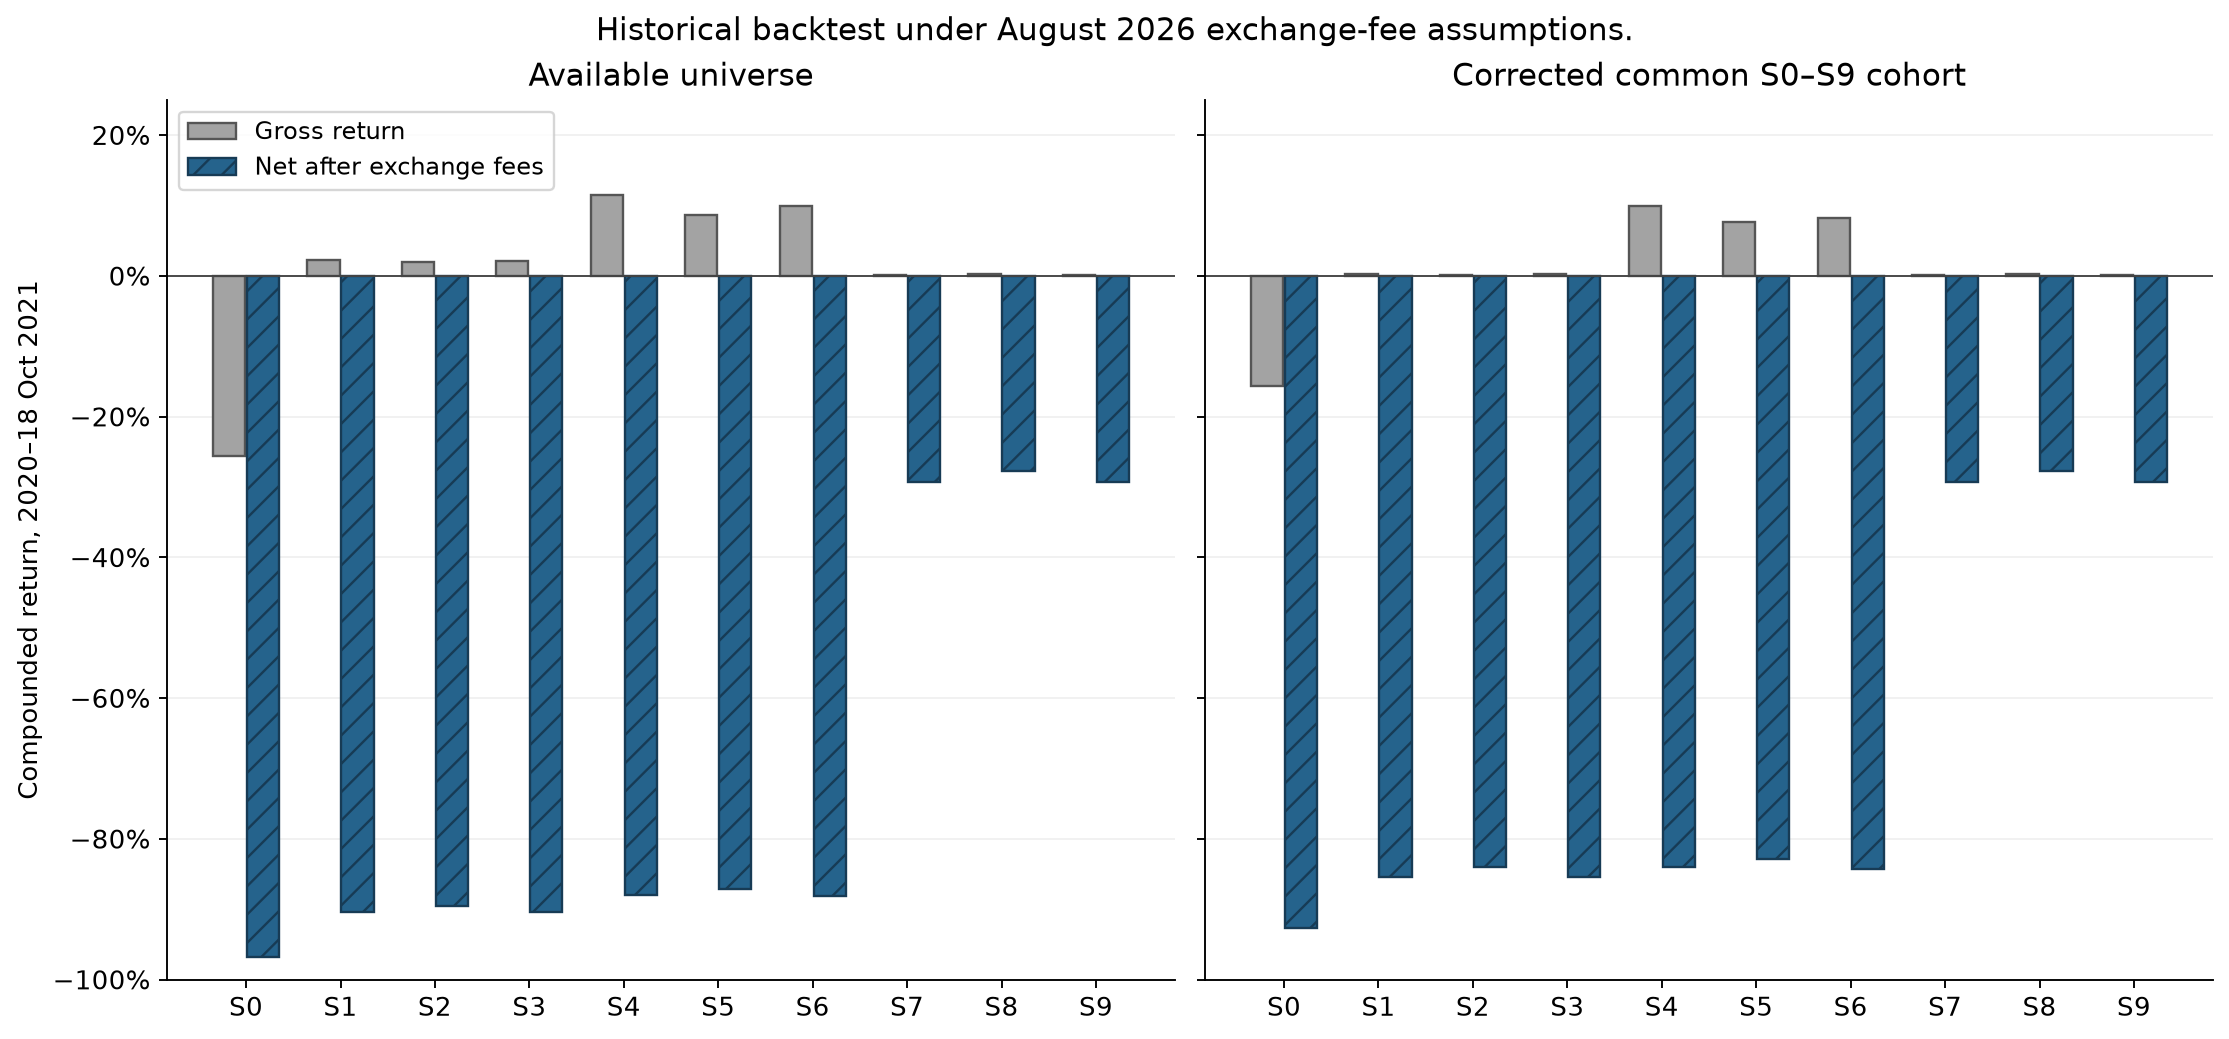

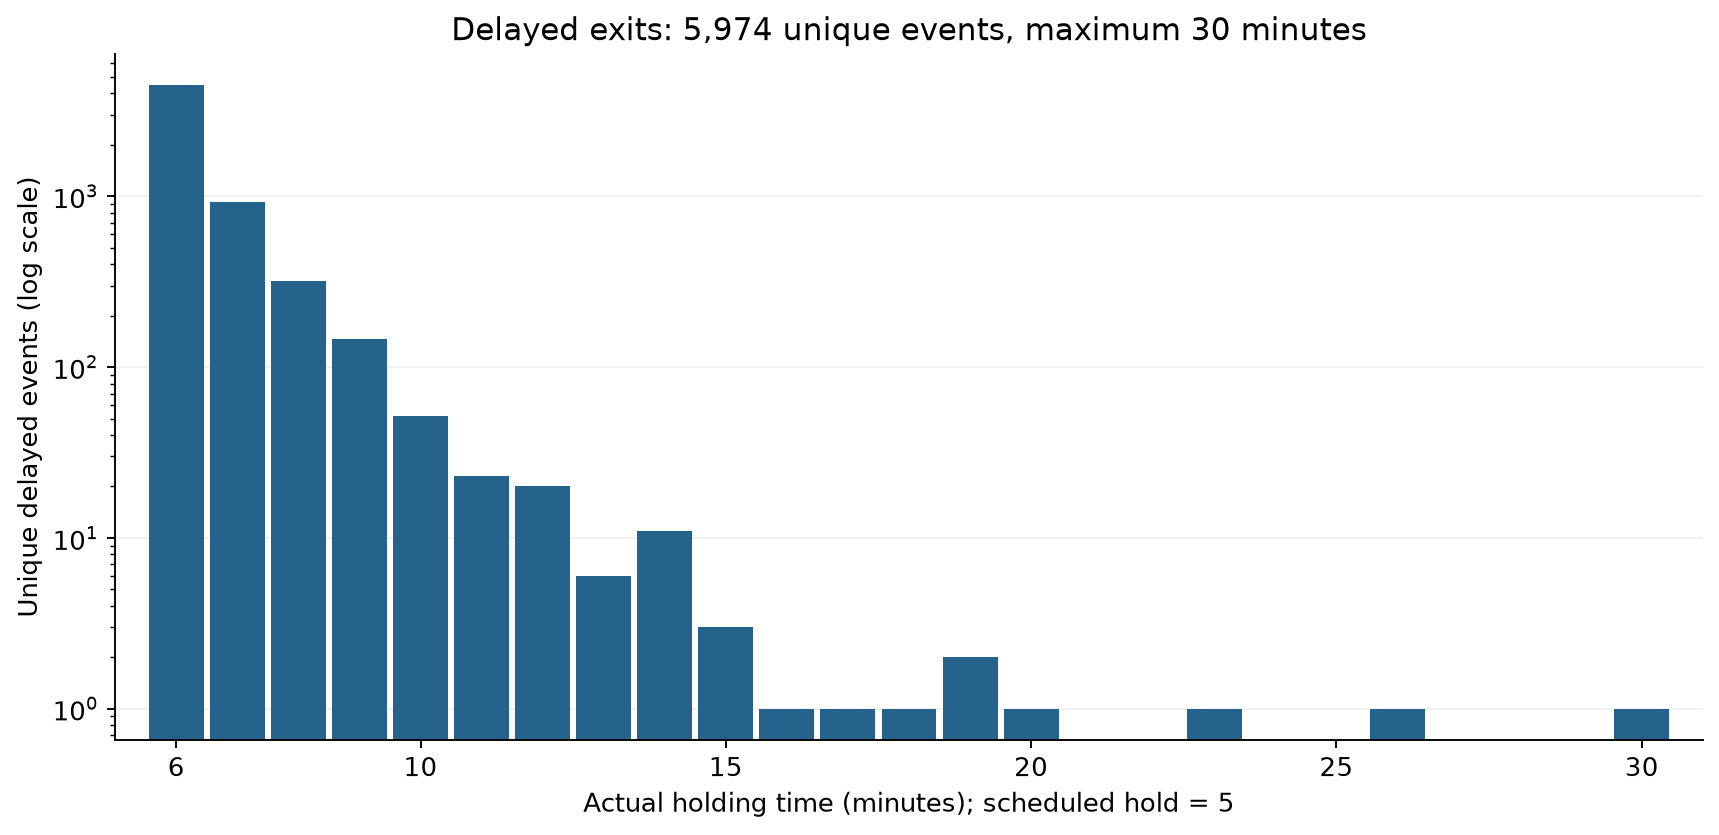

In [7]:
display(Image(filename=str(OUT/'audit_figures/strategy_comparison.png')))
display(Image(filename=str(OUT/'audit_figures/delayed_exit_distribution.png')))

In [8]:
display(Markdown((OUT/'presentation_findings.md').read_text()))

# MFT Futures Research — verified findings for Nikolai

**Historical backtest under August 2026 exchange-fee assumptions.**

**The main conclusion:** return distributions exhibit heavy tails and volatility clustering, but this research does not establish positive tradable alpha after the specified exchange fees.

## Return properties

Across 54 products in 2020–18 October 2021, median lag 1 return ACF is -0.0811; absolute-return ACF is 0.2314. Median excess kurtosis is 12.06; all 54 products have heavier 3-sigma tails than a Gaussian benchmark. These are descriptive minute-bar findings, including microstructure/zero-volume effects.

## Volatility forecasting

For the planned Notebook 08 holding window t+2…t+6, 54 products and 1,184,638 matched origins, median forecast/realized-volatility correlation is 0.5452 (GARCH), 0.5453 (GJR), 0.5450 (EWMA). Equal-product mean deltaQLIKE versus EWMA is -0.001858/-0.001977; 30/54 and 31/54 products improve. The gain is small and unstable: in 2021 the deltas turn positive (+0.000345/+0.000333), with only 25/54 and 25/54 products improving. QLIKE uses a floor of 1e-8×training variance.

Do not mix this window with 07's original t+1…t+5/common-all6 result: that original comparison has **worse** average GARCH/GJR QLIKE than EWMA. All scopes are preserved in the comparison CSV. Variable delayed-exit horizons are not scored by the fixed five-minute volatility table.

EGARCH also has 6 finite but extreme planned-hold variance forecasts above1 on 4 products. These were retained and independently reproduced; numerical convergence does not establish stable forecasting.

GJR estimates have larger negative-shock loadings on 46/53 original full-train files. This is descriptive asymmetry, without a coefficient-significance claim. SA is an explicit Notebook 08 extension with only 19 training dates; 07's original eligibility remains 53/54, and composite-model coverage is 46/54.

## Gross versus net

**28/47** tested available-universe variants have positive gross return; **0/47** have positive net return. S0–S9 have 9/10 positive gross results and 0/10 positive net results; corrected common-cohort results also have 0/10 positive net results. No test-period winner is selected.

| Strategy | Gross return | Net after exchange fees | Net + 0.5 bp/side | Net + 1 bp/side |
| --- | --- | --- | --- | --- |
| S0 | -25.61% | -96.76% | -99.46% | -99.91% |
| S1 | 2.19% | -90.46% | -98.09% | -99.62% |
| S2 | 1.99% | -89.54% | -97.79% | -99.53% |
| S3 | 2.15% | -90.47% | -98.09% | -99.62% |
| S4 | 11.54% | -87.92% | -97.11% | -99.31% |
| S5 | 8.60% | -87.12% | -96.76% | -99.19% |
| S6 | 9.85% | -88.11% | -97.16% | -99.32% |
| S7 | 0.14% | -29.25% | -43.86% | -55.47% |
| S8 | 0.21% | -27.73% | -41.96% | -53.40% |
| S9 | 0.12% | -29.28% | -43.90% | -55.51% |

The table shows separately compounded returns. Exchange-fee accounting contributions must use a common net-capital path; they are not gross compounded return minus net compounded return. Base includes exchange fees only. **Broker fees, bid-ask spread and slippage are excluded from the base**; 0.5/1 bp per side are additional sensitivity assumptions, not a complete transaction-cost model. I's unit divisor, AG contract-month scope and SC front-month treatment remain unresolved.

## Audit changes and limitations

Corrected the S0–S9 common mask, added fit-cache lineage validation, and included missing runtime settings in 07 cache keys. The pre-handoff input-validation and serialization corrections preserve every fitted coefficient and forecast; those predictions and scores are independently checked. All 47 original available-universe returns are unchanged; common-cohort values were recalculated. Independent full-ledger checks found no contract crossings or position overlaps. There are 5,974 distinct delayed-exit events, with maximum 30 minutes, including one RR intraday-break crossing; those positions remain in PnL.

The universe was selected retrospectively using some test history; 2020–2021 is not pristine. Execution is a close-price simulation, not bid/ask/order-book evidence. Fractional contracts and daily normalized capital differ from real lot/margin constraints. The exchange calendar and historical fee schedule are not reconstructed; broker charges, spread, impact and capacity are unverified. **Present this as a reproducible research experiment, not production-ready trading performance.**

Suggested verbal message: “We confirm heavy tails and volatility clustering. Some volatility forecasts show modest gains at the exact planned horizon, but those gains are unstable and do not translate into positive net performance under our exchange-fee scenarios. We fixed the common-cohort comparison and reconciled the PnL independently; the remaining limits are explicit.”


## Deliverables and explicit limits

- `artifacts/research_54/final_audit_07_08.md`
- `artifacts/research_54/final_strategy_comparison.csv`
- `artifacts/research_54/execution_diagnostics.csv`
- `artifacts/research_54/fee_audit.csv`
- `artifacts/research_54/volatility_model_comparison.csv`
- `artifacts/research_54/presentation_findings.md`

The source ambiguity for I, AG and SC, missing official historical trading-day calendar, retrospective universe/test, close-price fills, fractional lots and omitted broker/spread/impact/capacity remain documented limitations. Passing numerical tests does not remove them.